# Módulo: MODELOS DE INTELIGENCIA ARTIFICIAL
## Ejercicio práctico 1.
## Sistema Basado en Reglas   
### Análisis de la calidad del aire

De forma similar a lo realizado en el notebook SBR_IRIS, construye un sistema de clasificación de la calidad del aire (AirQuality - AQI) en función de la cantidad de Ozono detectado en el mismo.   
Los valores del nivel de AQI se muestran en la siguiente tabla:  


| NIVEL AQI | RANGO-DESCRIPCIÓN|
|:---------:|:----------------:|
|   BUENO   |     0 - 50       |
| MODERADO  |    51 - 100      |
|CONTAMINADO|   101 - 150      |
|  INSANO   |   151 - 200      |
| PELIGROSO |       > 200      |

Se pide intentar establecer la clasificación según la tabla anterior en base a alguna de las características que conforman el dataset (Valor de O2, Valor de CO, Valor de NO2, Valor de PM2.5, Longitud y Latitud).   
Como los datos son numéricos y no faltan valores, no se requiere ningún procesamiento previo.   

Nuestro objetivo es predecir el AQI, por lo que esta tarea sería de clasificación o de regresión, pero en este caso vamos a tratar de establecer un SBR basado en una de las variables independientes citadas.

<u>Nota sobre la característica ***PM2.5***</u> :   
Este valor se corresponde con la concentración del material particulado (*PM - Particulate Matter*) de la fracción de tamaño PM2,5 (2.5 micrometros), el cúal se encuentra íntimamente asociado a problemas de salud dado que entre sus efectos aparecen impactos claros sobre las enfermedades cardiacas y pulmonares.   

### NOTA A MAYORES
La columna AQI Value es la 'equivalente' a la etiqueta, que es la que utilizamos para "generar" la etiqueta final (Bueno, moderado,...) según lo establecido en la tabla del enunciado. Por tanto no podemos usar el target como variable a utilizar en las reglas. 

A través del EDA, debemos comprobar que variable "influye" más en determinar el AQI VALUE  y, por tanto, en la "etiqueta". Una vez tengamos esa variable (que se intuye fácilmente), deberemos montar las reglas y el motor de inferencia.

Importamos librerías necesarias

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbs

# Ocultamos los warnings de las librerías
import warnings
warnings.filterwarnings("ignore")
# ------------------------------------------------

Cargamos dataset *airquality.csv*

In [2]:
# Cargamos el dataset
data = pd.read_csv('datasets/airquality.csv')

Mostramos los primeros registros

In [3]:
data.head()

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,lat,lng
0,51,1,36,0,51,44.7444,44.2031
1,41,1,5,1,41,-5.2900,-44.4900
2,41,1,5,1,41,-11.2958,-41.9869
3,66,1,39,2,66,37.1667,15.1833
4,34,1,34,0,20,53.0167,20.8833


Asignación (mapeo) del nivel de calidad según los valores del mismo

In [4]:
def mapeo_calidad_aqi(row):
    if row["AQI Value"] > 50:
        if row["AQI Value"] > 100:
            if row["AQI Value"] > 150:
                if row["AQI Value"] > 200:
                    return "PELIGROSO"
                else:
                    return "INSANO"
            else:
                return "CONTAMINADO"
        else:
            return "MODERADO"
    else:
        return "BUENO"

data["AQI Level"] = data.apply(mapeo_calidad_aqi, axis=1)

Análisis breve del dataset (EDA)

1. Primera vista:

In [5]:
data.head()

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,lat,lng,AQI Level
0,51,1,36,0,51,44.7444,44.2031,MODERADO
1,41,1,5,1,41,-5.2900,-44.4900,BUENO
2,41,1,5,1,41,-11.2958,-41.9869,BUENO
3,66,1,39,2,66,37.1667,15.1833,MODERADO
4,34,1,34,0,20,53.0167,20.8833,BUENO


2. Vista de cantidades de datos con cada nivel AQI

In [6]:
display(data["AQI Level"].value_counts())

AQI Level
BUENO          7708
MODERADO       7081
CONTAMINADO     899
INSANO          814
PELIGROSO       193
Name: count, dtype: int64

3. Mapa de correlaciones

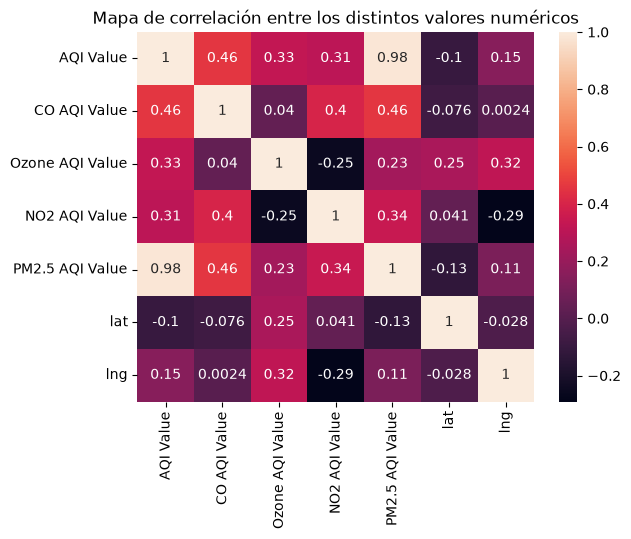

In [7]:
correlacion = data.drop(["AQI Level"], axis=1).corr()
plt.figure()
sbs.heatmap(
    correlacion,
    annot=True
)
plt.title("Mapa de correlación entre los distintos valores numéricos")
plt.show()

El dato con mas correlacion es el PM2.5, por lo que será nuestro motor de inferencia en la definición de reglas

Definición de reglas

In [8]:
def clasificar_basado_en_reglas(calidad_aqi_2_5):
    if calidad_aqi_2_5 > 50:
        if calidad_aqi_2_5 > 100:
            if calidad_aqi_2_5 > 150:
                if calidad_aqi_2_5 > 200:
                    return "Nodo 5 (PELIGROSO)"
                else:
                    return "Nodo 4 (INSANO)"
            else:
                return "Nodo 3 (CONTAMINADO)"
        else:
            return "Nodo 2 (MODERADO)"
    else:
        return "Nodo 1(BUENO)"    

Aplicación de reglas

In [9]:
def aplicar_reglas(row):
    return clasificar_basado_en_reglas(row["PM2.5 AQI Value"])

data["nodo"] = data.apply(aplicar_reglas, axis=1)

Visualización gráfica

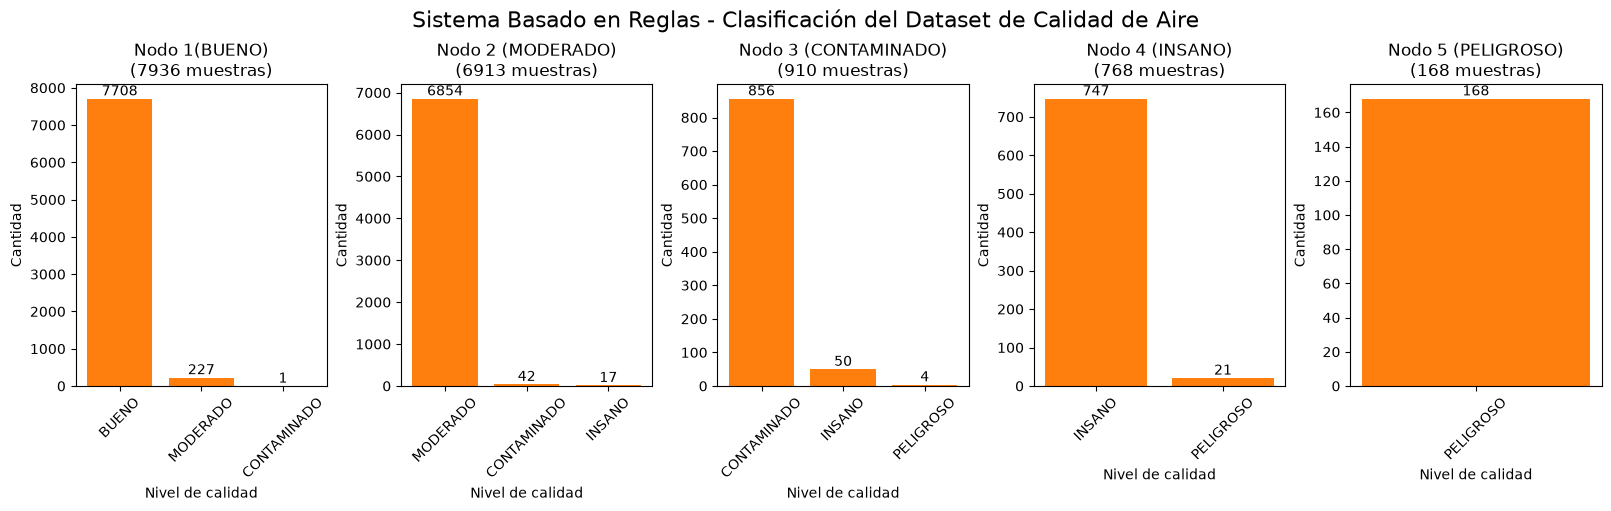

In [10]:
nodos_finales = data['nodo'].unique()
nodos_finales.sort()
fig, axes = plt.subplots(1, len(nodos_finales), figsize=(16, 5), constrained_layout=True)

for ax, nodo in zip(axes, nodos_finales):
    nodo_data = data[data['nodo'] == nodo]
    species_counts = nodo_data['AQI Level'].value_counts()
    # Crear las barras
    bars = ax.bar(species_counts.index, species_counts.values)
    
    # Añadir las cantidades encima de las barras
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,  # Posición horizontal (centro de la barra)
            height,  # Posición vertical (altura de la barra)
            str(height),  # Texto a mostrar (la cantidad)
            ha='center', va='bottom', fontsize=10  # Alineación y tamaño de fuente
        )
    
    # Configurar títulos y etiquetas
    ax.bar(species_counts.index, species_counts.values)
    ax.set_title(f"{nodo}\n({len(nodo_data)} muestras)")
    ax.set_xlabel("Nivel de calidad")
    ax.set_ylabel("Cantidad")
    ax.set_xticklabels(species_counts.index, rotation=45)

plt.suptitle("Sistema Basado en Reglas - Clasificación del Dataset de Calidad de Aire", fontsize=16)
plt.show()